# Virtual control groups from NTP historical controls: a walkthrough

This notebook walks through the proof of concept step by step on the processed
data produced by `python -m vcg.cli prepare`, and then loads the full results
produced by `evaluate` and `summarise`.

Everything here is a **comparison with the real concurrent control group**. A
virtual control group (VCG) conclusion is never treated as the truth; the
concurrent control conclusion is the reference, and we ask how often the VCG
would have led a toxicologist to the same place.

Requires the processed tables (`data/processed/`) and results (`results/`) to exist.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from vcg import config as C, prepare, matching as M, stats as S, evaluation as E

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
data = prepare.load_processed(C.PROCESSED_DIR)
studies, meas, roster, lesions = (data[k] for k in ("studies", "measurements", "animals", "lesions"))
print({k: v.shape for k, v in data.items()})

{'studies': (1985, 12), 'measurements': (1006700, 11), 'animals': (196004, 11), 'lesions': (1705213, 8)}


## 1. What is in the data

Only F344 rats and B6C3F1/N mice from simple dose-response designs are kept:
3-month ("subchronic") studies and 2-year ("chronic") studies. The study table
carries the attributes used for matching.

In [2]:
studies.groupby(["species", "design"]).agg(studies=("study", "nunique"), labs=("laboratory", "nunique"),
                                            first_year=("year", "min"), last_year=("year", "max"))

studies  labs  first_year  last_year
species design                                          
Mouse   chronic         819    26      1971.0     2013.0
        subchronic      247    18      1981.0     2016.0
Rat     chronic         698    24      1971.0     2005.0
        subchronic      221    14      1981.0     2005.0

In [3]:
(meas.merge(studies[["study", "design"]], on="study")
     .groupby(["domain", "design"]).agg(studies=("study", "nunique"), animals=("animal", "nunique"),
                                        endpoints=("endpoint", "nunique"))
     .reset_index().pivot(index="domain", columns="design", values=["studies", "endpoints"]))

studies            endpoints           
design       chronic subchronic   chronic subchronic
domain                                              
clin_chem        NaN      123.0       NaN        9.0
hematology       NaN      190.0       NaN       13.0
inlife_bw      219.0      373.0       4.0        3.0
organ_weight     NaN      254.0       NaN        6.0
terminal_bw    467.0      368.0       1.0        1.0

In [4]:
studies["laboratory"].value_counts().head(12)

laboratory
Battelle Columbus                      337
TSI Mason Research                     325
Southern Research                      325
Battelle Northwest                     181
Litton Bionetics                       169
Hazleton                               141
Frederick Cancer Research Facility     106
BioReliance                             87
Gulf South Research Institute           66
Physiological Research Laboratories     48
IIT Research Institute                  28
<NA>                                    24
Name: count, dtype: int64

## 2. One study, one endpoint, by hand

We take a 3-month rat study with clinical chemistry, hold out its concurrent
control group, and build virtual control groups from other studies at
increasing matching strictness.

In [5]:
cands = meas[(meas["domain"] == "clin_chem") & (meas["sex"] == "Male")].merge(
    studies[["study", "species", "laboratory", "route", "vehicle", "year", "test_article"]], on="study")
cands = cands[(cands["species"] == "Rat") & (cands["laboratory"] == "Battelle Columbus") & (cands["route"] == "Gavage")]
example = cands.sort_values("year")["study"].iloc[len(cands["study"].unique()) // 2] if len(cands) else meas["study"].iloc[0]
row = studies.set_index("study").loc[example]
print(example, "|", row["test_article"], "|", row["route"], row["vehicle"], "|", row["laboratory"], int(row["year"]))
target = M.target_from_row(pd.Series({"study": example, **row.to_dict()}), "Male")
target

002-02624-0006-0000-2 | Oxymetholone | Gavage Methylcellulose, 0.5% | Battelle Columbus 1992


Target(study='002-02624-0006-0000-2', sex='Male', species='Rat', strain='F344', design='subchronic', route='Gavage', vehicle='Methylcellulose, 0.5%', laboratory='Battelle Columbus', year=1992.0, dtxsid='DTXSID5023794')

In [6]:
endpoint = "ALT"
d = meas[(meas["study"] == example) & (meas["sex"] == "Male") & (meas["endpoint"] == endpoint)]
conc = d.loc[d["is_control"], "value"].to_numpy()
doses = sorted(d.loc[~d["is_control"], "dose"].unique())
groups = [d.loc[d["dose"] == x, "value"].to_numpy() for x in doses]
print("concurrent controls:", len(conc), "animals; dose groups:", doses)
ref = S.dunnett(groups, conc)
pd.DataFrame({"dose": doses, "mean": [g.mean() for g in groups], "t": ref.statistic.round(2), "p_dunnett": ref.pvalue.round(4)})

concurrent controls: 10 animals; dose groups: [np.float64(80.0), np.float64(160.0), np.float64(315.0), np.float64(625.0), np.float64(1250.0)]


,dose,mean,t,p_dunnett
0,80.0,49.100000,-1.28,0.5795
1,160.0,44.200000,-2.94,0.0210
2,315.0,42.700000,-3.45,0.0051
3,625.0,35.777778,-5.63,0.0000
4,1250.0,38.555556,-4.72,0.0001


In [7]:
# historical control animals for this endpoint, with study metadata
hist = E._controls_with_metadata(meas[meas["endpoint"] == endpoint], studies)
hist = hist[(hist["species"] == "Rat") & (hist["sex"] == "Male") & (hist["design"] == target.design)]
pools = {lvl: M.pool_mask(hist, target, crit) for lvl, crit in C.MATCH_LEVELS.items()}
pd.DataFrame({lvl: M.describe_pool(hist, m) for lvl, m in pools.items()}).T

,n_animals,n_studies,n_labs
L0 design,739,72,8
L1 +route,240,23,4
L2 +vehicle,100,9,3
L3 +laboratory,50,5,1
L4 +period (3y),40,4,1


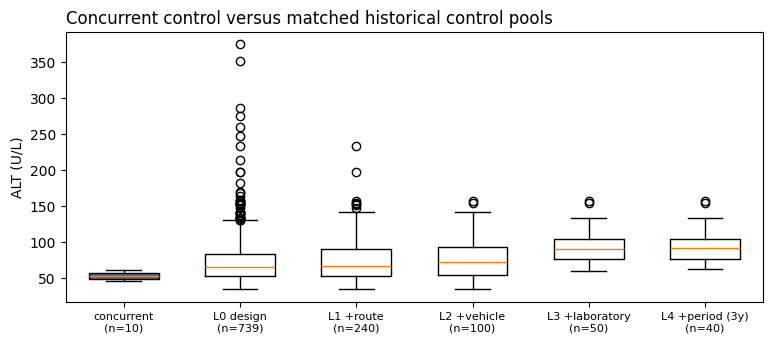

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.5))
positions, labels = [], []
ax.boxplot([conc], positions=[0], widths=0.6, patch_artist=True, boxprops=dict(facecolor="#3b6ea5"))
labels.append(f"concurrent\n(n={len(conc)})")
for i, (lvl, m) in enumerate(pools.items(), start=1):
    vals = hist.loc[m, "value"].to_numpy()
    if len(vals):
        ax.boxplot([vals], positions=[i], widths=0.6)
    labels.append(f"{lvl}\n(n={len(vals)})")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel(f"{endpoint} ({d['unit'].iloc[0]})"); ax.set_title("Concurrent control versus matched historical control pools", loc="left")
plt.show()

Now draw virtual control groups of the same size as the concurrent group and
repeat the Dunnett test. The question is not whether the p-values are equal but
whether the *conclusion* (significant at 5% or not, per dose group) is.

In [9]:
rng = np.random.default_rng(0)
rows = []
for lvl, m in pools.items():
    pool = hist.loc[m, "value"].to_numpy()
    if len(pool) < 2 * len(conc):
        continue
    for k in range(20):
        vcg = M.draw_vcg(pool, len(conc), rng)
        res = S.dunnett(groups, vcg)
        for r, x in enumerate(doses):
            rows.append(dict(level=lvl, draw=k, dose=x, sig_conc=ref.pvalue[r] < 0.05, sig_vcg=res.pvalue[r] < 0.05))
ex = pd.DataFrame(rows)
ex["agree"] = ex["sig_conc"] == ex["sig_vcg"]
ex.groupby(["level", "dose"])[["sig_conc", "sig_vcg", "agree"]].mean().round(2)

sig_conc  sig_vcg  agree
level           dose                            
L0 design       80.0         0.0     0.90   0.10
                160.0        1.0     1.00   1.00
                315.0        1.0     1.00   1.00
                625.0        1.0     1.00   1.00
                1250.0       1.0     1.00   1.00
L1 +route       80.0         0.0     0.95   0.05
                160.0        1.0     1.00   1.00
                315.0        1.0     1.00   1.00
                625.0        1.0     1.00   1.00
                1250.0       1.0     1.00   1.00
L2 +vehicle     80.0         0.0     1.00   0.00
                160.0        1.0     1.00   1.00
                315.0        1.0     1.00   1.00
                625.0        1.0     1.00   1.00
                1250.0       1.0     1.00   1.00
L3 +laboratory  80.0         0.0     1.00   0.00
                160.0        1.0     1.00   1.00
                315.0        1.0     1.00   1.00
                625.0        1.0     1.00   1.00
                1250.0       1.0     1.00   1.00
L4 +period (3y) 80.0         0.0     1.00   0.00
                160.0        1.0     1.00   1.00
                315.0        1.0     1.00   1.00
                625.0        1.0     1.00   1.00
                1250.0       1.0     1.00   1.00

## 3. Full results

`python -m vcg.cli evaluate` repeats this for every study, sex, endpoint and dose
group, at every matching level, for full and partial VCGs, and for pools
restricted to time-gap bands. `summarise` aggregates the draws.

In [10]:
summary = json.loads((C.RESULTS_DIR / "summary.json").read_text())
{k: v for k, v in summary.items() if k not in ("figures",)}

{'headline_level': 'L3 +laboratory',
 'agreement': 0.7734,
 'false_positive': 0.1723,
 'false_negative': 0.0544,
 'fp_given_conc_nonsig': 0.2365,
 'fn_given_conc_sig': 0.2002,
 'sensitivity': 0.7998,
 'specificity': 0.7635,
 'kappa': 0.4958,
 'trivial_agreement_never_significant': 0.7285,
 'concurrent_significant_rate': 0.2715,
 'vcg_significant_rate': 0.3894,
 'n_endpoint_units': 26118,
 'n_studies': 1120,
 'n_study_sex_units': 1591,
 'n_records': 27474820,
 'n_draws': 20,
 'studies_in_processed_data': 1985,
 'by_level': {'L0 design': {'agreement': 0.7284,
   'kappa': 0.4282,
   'coverage_units': 35729},
  'L1 +route': {'agreement': 0.7402, 'kappa': 0.4462, 'coverage_units': 35397},
  'L2 +vehicle': {'agreement': 0.7571,
   'kappa': 0.4728,
   'coverage_units': 32809},
  'L3 +laboratory': {'agreement': 0.7734,
   'kappa': 0.4958,
   'coverage_units': 26118},
  'L4 +period (3y)': {'agreement': 0.7938,
   'kappa': 0.5348,
   'coverage_units': 21464}},
 'partial_by_level': {'L0 design': 

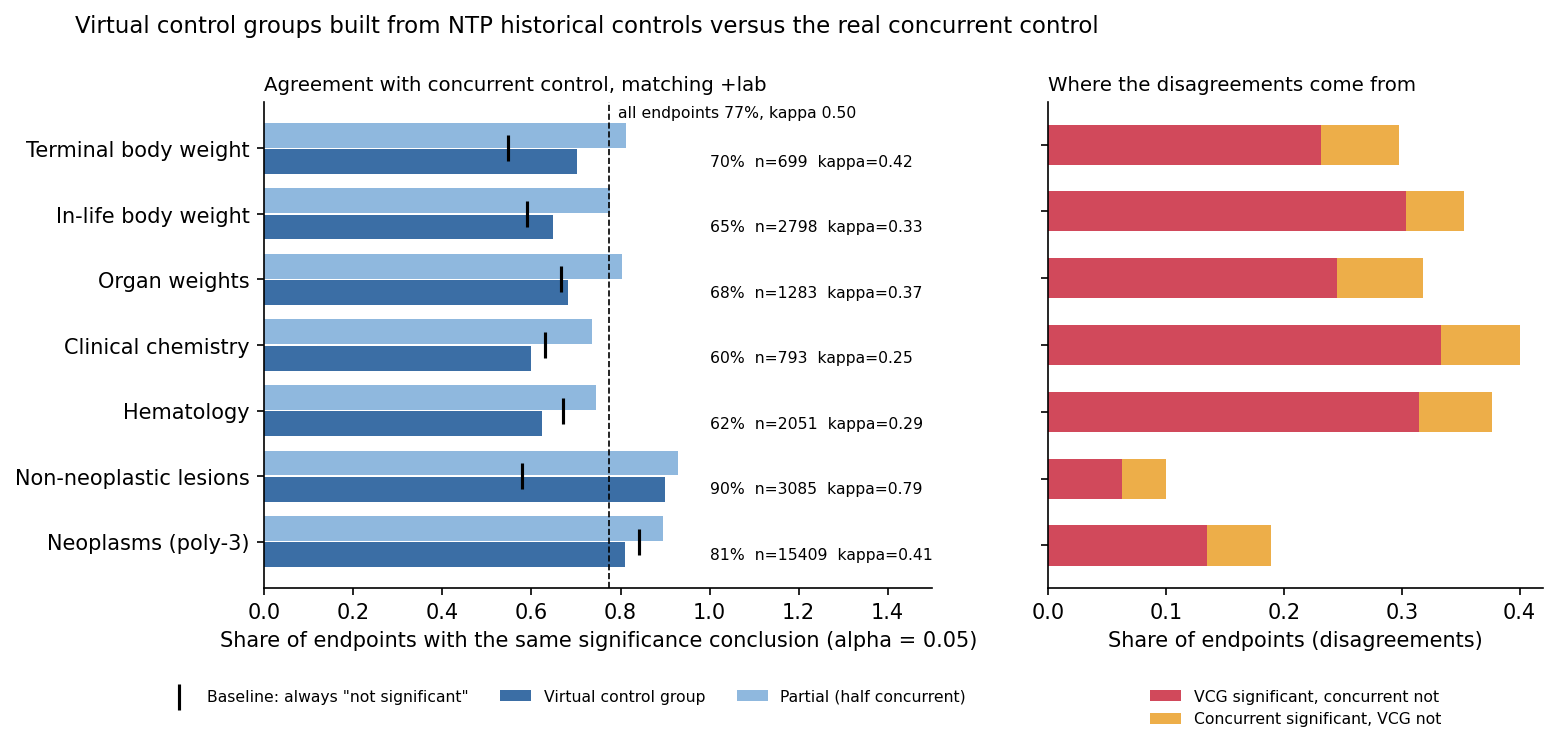

In [11]:
display(Image(filename=str(C.FIGURES_DIR / "headline_agreement.png"), width=1000))

In [12]:
lvl = summary["headline_level"]
t = pd.read_csv(C.TABLES_DIR / "agreement_by_domain_level.csv")
cols = ["domain", "n_endpoints", "agreement", "false_positive", "false_negative", "fp_given_conc_nonsig", "fn_given_conc_sig", "conc_sig_rate", "vcg_sig_rate"]
t[(t["mode"] == "vcg") & (t["level"] == lvl)][cols].set_index("domain").round(3)

,n_endpoints,agreement,false_positive,false_negative,fp_given_conc_nonsig,fn_given_conc_sig,conc_sig_rate,vcg_sig_rate
domain,,,,,,,,
organ_weight,1283,0.682,0.245,0.072,0.368,0.217,0.334,0.507
terminal_bw,699,0.703,0.231,0.066,0.422,0.146,0.452,0.617
inlife_bw,2798,0.648,0.304,0.049,0.514,0.120,0.409,0.664
nonneoplastic lesion,3085,0.900,0.062,0.038,0.148,0.066,0.579,0.604
neoplasm,15409,0.811,0.134,0.055,0.160,0.346,0.159,0.238
clin_chem,793,0.600,0.334,0.066,0.530,0.179,0.371,0.638
hematology,2051,0.623,0.315,0.062,0.470,0.188,0.330,0.583


### Matching strictness and coverage

Each level adds one criterion. Stricter matching should make the pool more
similar to the concurrent group, but it also shrinks the pool: coverage is the
share of study/sex/endpoint units for which a pool of at least twice the control
group size exists.

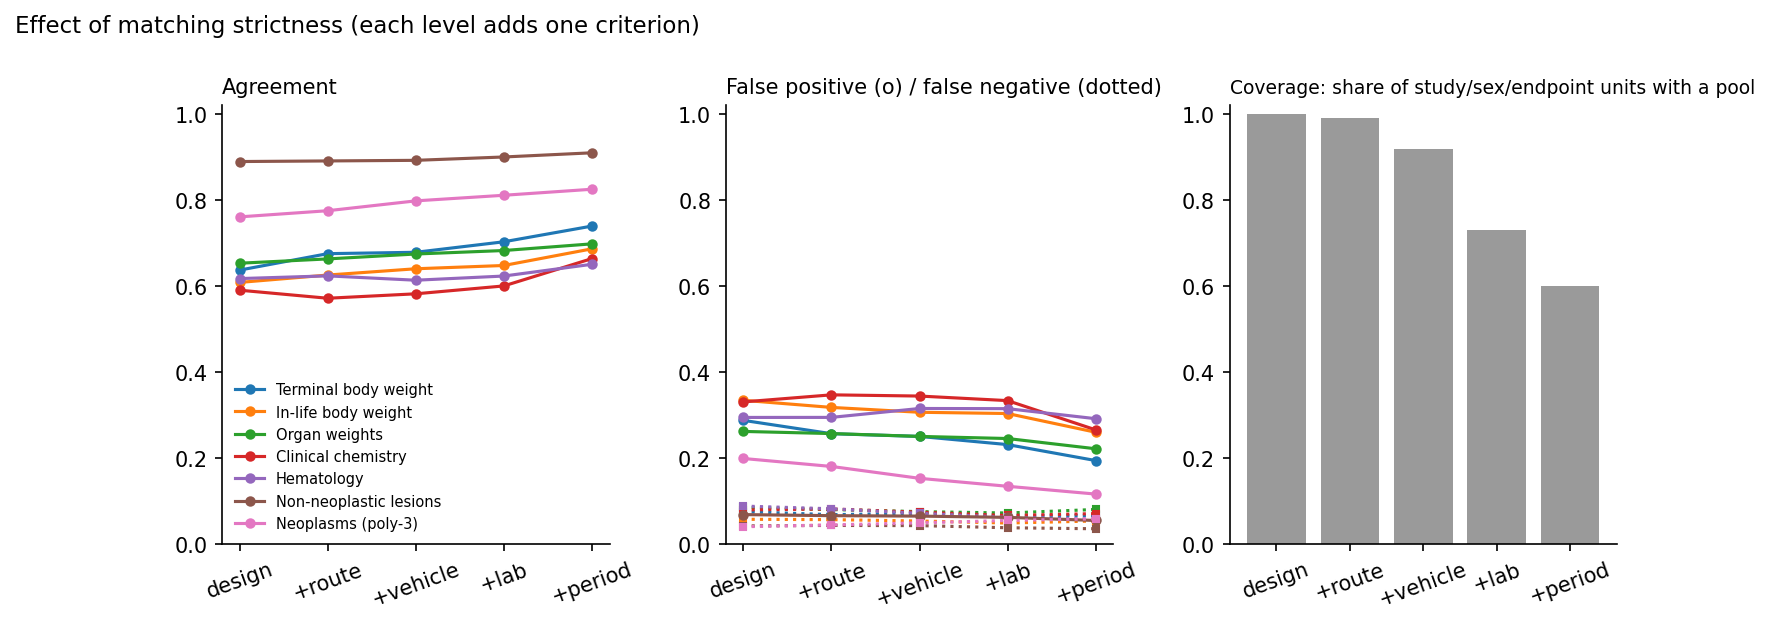

,mode,level,n_endpoints,agreement,false_positive,false_negative,conc_sig_rate,vcg_sig_rate,kappa,trivial_agreement,fp_given_conc_nonsig,fn_given_conc_sig,sensitivity,specificity
0,vcg,L0 design,35729,0.728,0.220,0.052,0.277,0.444,0.428,0.723,0.303,0.188,0.812,0.697
1,vcg,L1 +route,35397,0.740,0.206,0.054,0.278,0.430,0.446,0.722,0.286,0.193,0.807,0.714
2,vcg,L2 +vehicle,32809,0.757,0.189,0.054,0.277,0.412,0.473,0.723,0.261,0.195,0.805,0.739
3,vcg,L3 +laboratory,26118,0.773,0.172,0.054,0.272,0.389,0.496,0.728,0.236,0.200,0.800,0.764
4,vcg,L4 +period (3y),21464,0.794,0.149,0.057,0.279,0.371,0.535,0.721,0.207,0.205,0.795,0.793
5,partial,L0 design,35729,0.835,0.118,0.047,0.277,0.347,0.617,0.723,0.163,0.171,0.829,0.837
6,partial,L1 +route,35447,0.843,0.109,0.048,0.278,0.339,0.634,0.722,0.151,0.172,0.828,0.849
7,partial,L2 +vehicle,34468,0.849,0.102,0.049,0.278,0.331,0.645,0.722,0.141,0.176,0.824,0.859
8,partial,L3 +laboratory,30910,0.861,0.093,0.046,0.276,0.324,0.670,0.724,0.129,0.166,0.834,0.871
9,partial,L4 +period (3y),28175,0.871,0.083,0.046,0.282,0.319,0.693,0.718,0.115,0.164,0.836,0.885


In [13]:
display(Image(filename=str(C.FIGURES_DIR / "agreement_vs_strictness.png"), width=1000))
pd.read_csv(C.TABLES_DIR / "agreement_by_level.csv").round(3)

In [14]:
pd.read_csv(C.TABLES_DIR / "coverage_by_level.csv").round(3)

,level,n_units,coverage
0,L0 design,35729,1.000
1,L1 +route,35397,0.991
2,L2 +vehicle,32809,0.918
3,L3 +laboratory,26118,0.731
4,L4 +period (3y),21464,0.601


### Partial virtual control groups

Half of the concurrent control animals are kept and the other half is replaced
by historical animals.

In [15]:
t = pd.read_csv(C.TABLES_DIR / "agreement_by_level.csv")
t.pivot(index="level", columns="mode", values=["agreement", "false_positive", "false_negative"]).round(3)

agreement        false_positive        false_negative       
mode              partial    vcg        partial    vcg        partial    vcg
level                                                                       
L0 design           0.835  0.728          0.118  0.220          0.047  0.052
L1 +route           0.843  0.740          0.109  0.206          0.048  0.054
L2 +vehicle         0.849  0.757          0.102  0.189          0.049  0.054
L3 +laboratory      0.861  0.773          0.093  0.172          0.046  0.054
L4 +period (3y)     0.871  0.794          0.083  0.149          0.046  0.057

### Drift: time between historical and current study

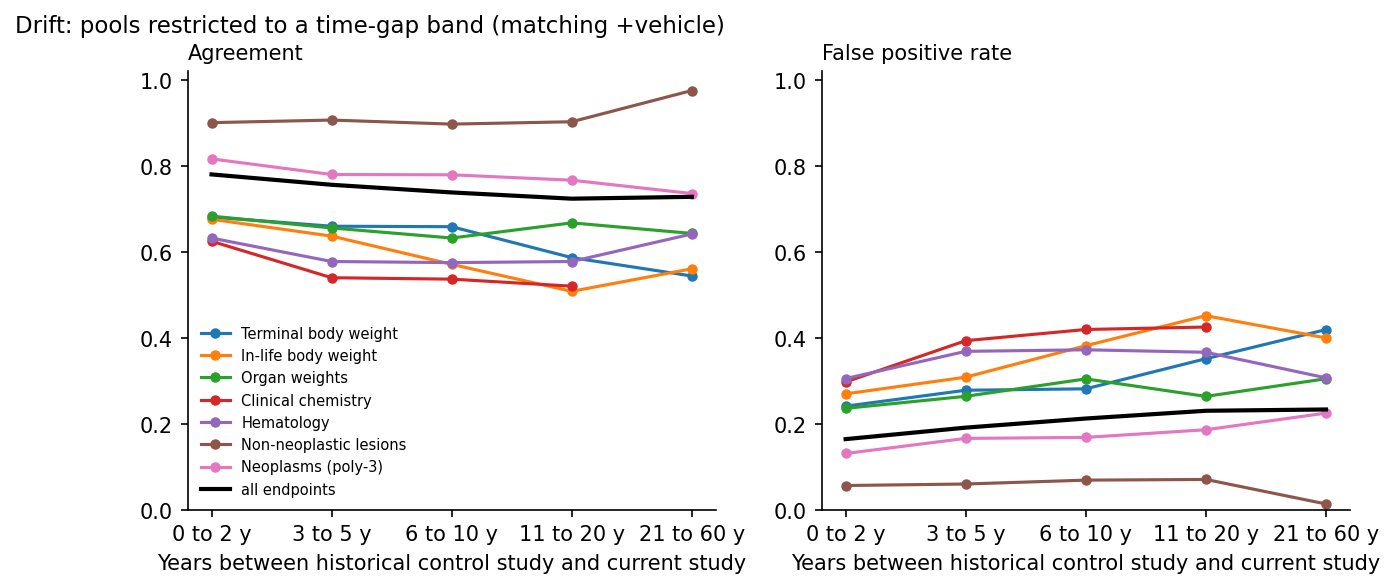

,mode,level,band,n_endpoints,agreement,false_positive,false_negative,conc_sig_rate,vcg_sig_rate,kappa,trivial_agreement,fp_given_conc_nonsig,fn_given_conc_sig,sensitivity,specificity
0,vcg,L2 +vehicle,0-2,26296,0.780,0.165,0.055,0.278,0.388,0.511,0.722,0.228,0.198,0.802,0.772
1,vcg,L2 +vehicle,6-10,17498,0.738,0.213,0.049,0.284,0.448,0.452,0.716,0.297,0.172,0.828,0.703
2,vcg,L2 +vehicle,3-5,18890,0.756,0.192,0.052,0.278,0.417,0.473,0.722,0.266,0.188,0.812,0.734
3,vcg,L2 +vehicle,21-60,7939,0.728,0.234,0.038,0.212,0.408,0.391,0.788,0.297,0.180,0.820,0.703
4,vcg,L2 +vehicle,11-20,15391,0.724,0.231,0.045,0.263,0.448,0.419,0.737,0.313,0.173,0.827,0.687


In [16]:
display(Image(filename=str(C.FIGURES_DIR / "agreement_vs_time_gap.png"), width=900))
pd.read_csv(C.TABLES_DIR / "agreement_by_drift.csv").query("mode == 'vcg'").round(3)

### Which endpoints are suitable?

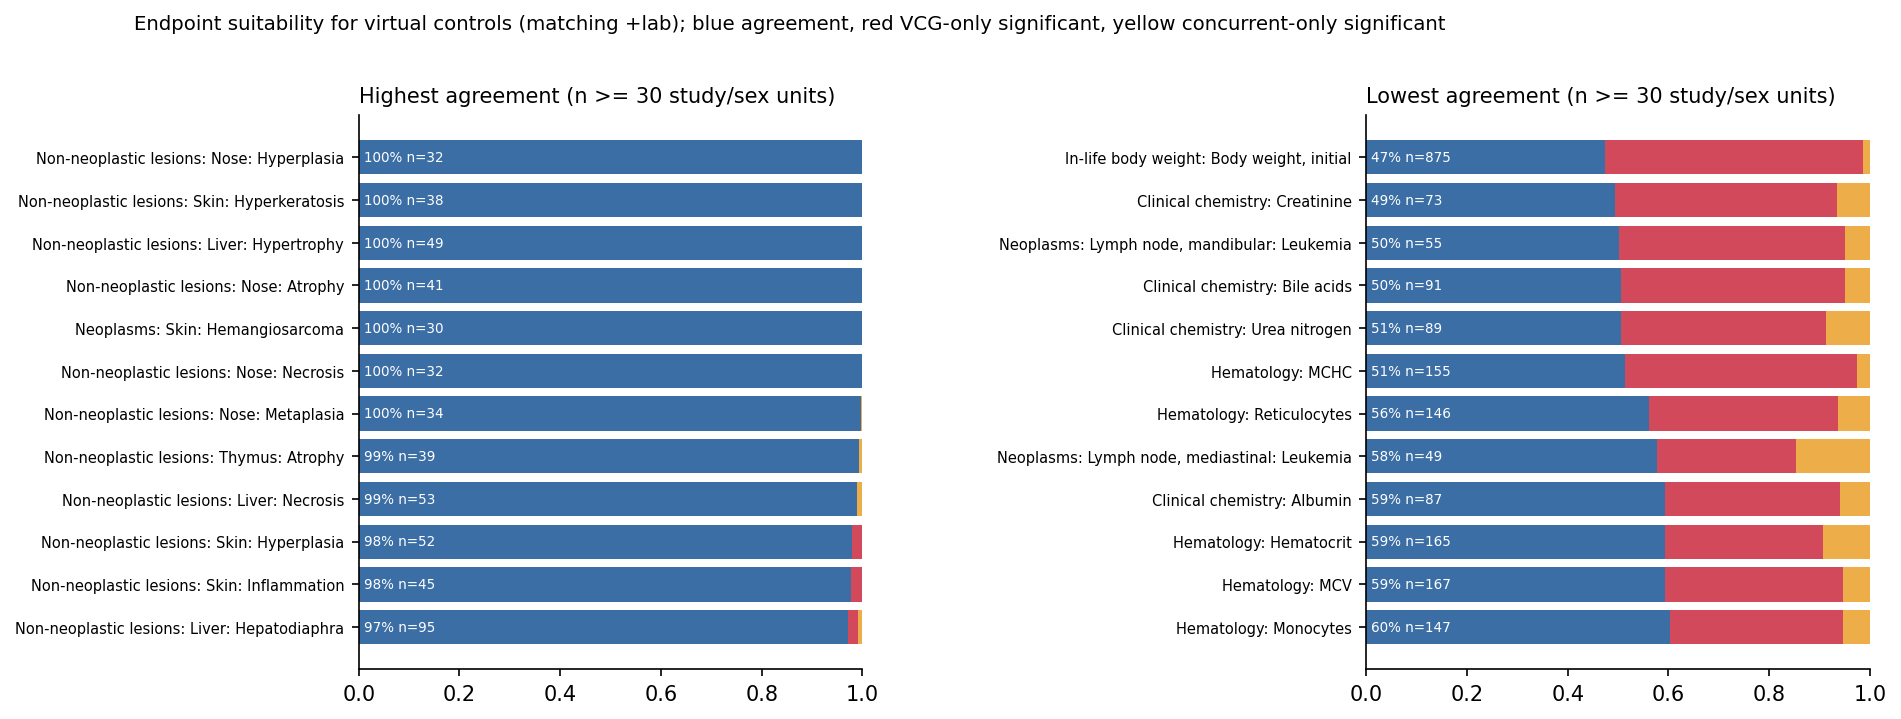

,domain,endpoint,n_endpoints,agreement,false_positive,false_negative
18,inlife_bw,"Body weight, initial",875,0.473,0.513,0.014
964,clin_chem,Creatinine,73,0.494,0.440,0.066
1714,neoplasm,"Lymph node, mandibular: Leukemia",55,0.501,0.449,0.050
960,clin_chem,Bile acids,91,0.505,0.446,0.050
970,clin_chem,Urea nitrogen,89,0.505,0.407,0.088
1019,hematology,MCHC,155,0.513,0.462,0.025
1347,hematology,Reticulocytes,146,0.562,0.374,0.064
1103,neoplasm,"Lymph node, mediastinal: Leukemia",49,0.578,0.276,0.147
1670,nonneoplastic lesion,Thymus: Atrophy,39,0.994,0.000,0.006
1397,nonneoplastic lesion,Nose: Metaplasia,34,0.997,0.000,0.003


In [17]:
display(Image(filename=str(C.FIGURES_DIR / "endpoint_suitability.png"), width=1000))
t = pd.read_csv(C.TABLES_DIR / "agreement_by_endpoint.csv")
t = t[(t["level"] == lvl) & (t["n_endpoints"] >= 30)].sort_values("agreement")
pd.concat([t.head(8), t.tail(8)])[["domain", "endpoint", "n_endpoints", "agreement", "false_positive", "false_negative"]].round(3)

### Does the concurrent control itself look like the virtual one?

For continuous endpoints we also tested the concurrent control group against each
drawn VCG (Welch t-test). The share of significant differences is a direct
measure of how often the historical pool does not represent the current
control group, independent of any treatment effect.

In [18]:
pd.read_csv(C.TABLES_DIR / "control_vs_vcg.csv").pivot(index="domain", columns="level", values="share_concurrent_differs_from_vcg").round(3)

level,L0 design,L1 +route,L2 +vehicle,L3 +laboratory,L4 +period (3y)
domain,,,,,
clin_chem,0.378,0.394,0.421,0.402,0.329
hematology,0.318,0.323,0.352,0.344,0.341
inlife_bw,0.468,0.446,0.428,0.392,0.325
organ_weight,0.278,0.266,0.268,0.255,0.219
terminal_bw,0.404,0.358,0.343,0.287,0.214


## 4. Reading the results

* Agreement is high for endpoints with little between-study variation and low
  for endpoints that drift between laboratories and decades.
* Disagreements are mostly *extra* significant findings with the VCG (false
  positives relative to the concurrent control), which is what one expects when
  the historical pool is shifted relative to the current study.
* Partial VCGs recover part of the lost agreement.
* All of this is a retrospective comparison on public NTP data with the matching
  attributes available in CEBS. It is not a regulatory validation. See the README
  for the limitations.